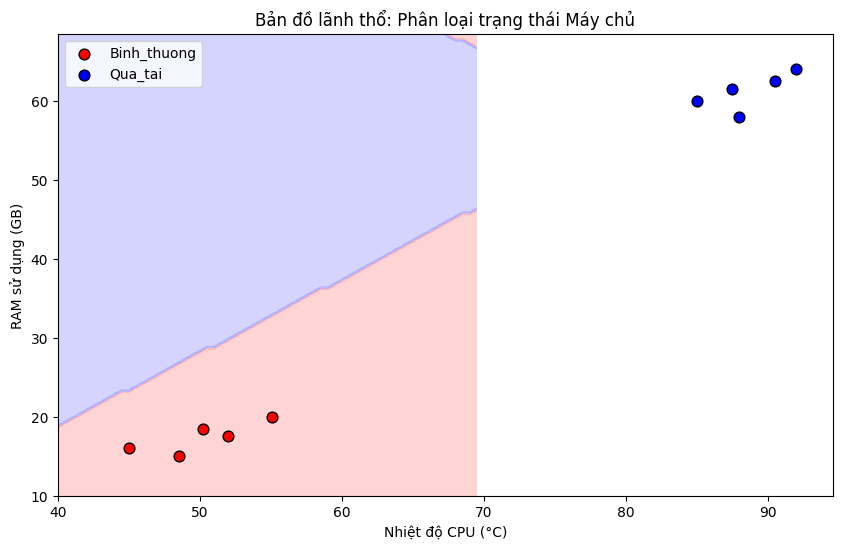

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


class ServerGaussianNB:
    def __init__(self, eps=1e-9):
        self.eps = eps
        self.classes = None
        self.mean = {}
        self.var = {}
        self.priors = {}

    def fit(self, X, y):
        N, d = X.shape
        self.classes = np.unique(y)

        for c in self.classes:# c là đặc trưng ví dụ binh thường hay quá tải 
            # TODO 1: Lọc dữ liệu theo lớp c và tính Prior, Mean (mu), Variance (sigma^2)
            # self.priors[c] = ...
            # self.mean[c] = ...
            # self.var[c] = ... (nhớ cộng self.eps để chống chia cho 0)
            X_c=X[y==c]# lọc data để tránh cùng mean với 2 đặc trưng
            self.priors[c]=X.shape[0]/N
            self.mean[c]=np.mean(X_c,axis=0)/N
            self.var[c]=np.var(X_c,axis=0)+self.eps

    def _calculate_pdf(self, x, mean, var):
        # TODO 2: Triển khai công thức hàm mật độ xác suất (PDF) của phân phối chuẩn
        # pdf = ...
        # return pdf
        pdf=np.exp(-(x-mean)**2/(2*var))/np.sqrt(2*np.pi*var)
        return pdf

    def predict(self, X):
        predictions = []
        for x in X:
            posteriors = []
            for c in self.classes:
                prior = self.priors[c]
                # Nhân xác suất tiên nghiệm với Mật độ của Nhiệt độ và RAM
                likelihood = np.prod(self._calculate_pdf(x, self.mean[c], self.var[c]))
                posteriors.append(prior * likelihood)
            predictions.append(self.classes[np.argmax(posteriors)])
        return np.array(predictions)

    def plot_decision_boundary(self, X, y):
        """Vẽ Bản đồ lãnh thổ (Decision Boundary) cho 2 đặc trưng"""
        # Tạo lưới tọa độ (Meshgrid) bao trùm không gian dữ liệu
        x_min, x_max = X[:, 0].min() - 5, X[:, 0].min() + 25
        y_min, y_max = X[:, 1].min() - 5, X[:, 1].max() + 5
        xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 0.5))

        # Dự đoán cho từng điểm trên lưới
        grid_points = np.c_[xx.ravel(), yy.ravel()]
        Z_str = self.predict(grid_points)

        # Chuyển đổi nhãn chuỗi thành số để tô màu
        label_map = {self.classes[0]: 0, self.classes[1]: 1}
        Z = np.array([label_map[lbl] for lbl in Z_str]).reshape(xx.shape)
        y_numeric = np.array([label_map[lbl] for lbl in y])

        # Vẽ Contour và Scatter
        plt.figure(figsize=(10, 6))
        cmap_light = ListedColormap(["#FFAAAA", "#AAAAFF"])
        cmap_bold = ["red", "blue"]

        plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.5)
        for idx, color in enumerate(cmap_bold):
            plt.scatter(
                X[y_numeric == idx, 0],
                X[y_numeric == idx, 1],
                c=color,
                label=self.classes[idx],
                edgecolor="k",
                s=60,
            )

        plt.title("Bản đồ lãnh thổ: Phân loại trạng thái Máy chủ")
        plt.xlabel("Nhiệt độ CPU (°C)")
        plt.ylabel("RAM sử dụng (GB)")
        plt.legend()
        plt.show()


# ================= DỮ LIỆU HUẤN LUYỆN =================
# X: [Nhiệt độ CPU, RAM]
X_train = np.array(
    [
        [45.0, 16.0],
        [50.2, 18.5],
        [55.1, 20.0],
        [48.5, 15.0],
        [52.0, 17.5],  # Bình thường
        [85.0, 60.0],
        [90.5, 62.5],
        [88.0, 58.0],
        [92.0, 64.0],
        [87.5, 61.5],  # Quá tải
    ]
)
y_train = np.array(
    [
        "Binh_thuong",
        "Binh_thuong",
        "Binh_thuong",
        "Binh_thuong",
        "Binh_thuong",
        "Qua_tai",
        "Qua_tai",
        "Qua_tai",
        "Qua_tai",
        "Qua_tai",
    ]
)

# Chạy thử sau khi code xong:
model = ServerGaussianNB()
model.fit(X_train, y_train)
model.plot_decision_boundary(X_train, y_train)


# Tạo thử X_test để test model